# 10 . Brainnetome 246 to Glasser52 mapping

Sid's MEG-GPT runs on **Glasser52** (Kohl et al. 2023, Zenodo 10401793), because its
tokeniser enforces 52 channels. We are on Brainnetome 210. To compare the two models on
identical inputs, we map our regions onto his parcels.

Both atlases are MNI volumes, so the mapping is spatial overlap. For each Brainnetome
region we count how many of its voxels fall inside each Glasser parcel, then average our
region time series into 52 using those counts as weights.

Outputs `glasser_W.npy` (210 x 52 weights), plus geometry `parcel_L_glasser52.npy` and
`parcel_S_glasser52.npy` built the same centroid way as notebook 00.

In [15]:
import os, sys
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import numpy as np, nibabel as nib
import matplotlib.pyplot as plt

DATA    = '../data'
BN      = f'{DATA}/brainnetome_atlas/BN_Atlas_246_2mm.nii.gz'
GLASSER = f'{DATA}/glasser52/Glasser52_binary_space-MNI152NLin6_res-8x8x8.nii.gz'
OUT     = '../results_parcel'
SUFFIX  = 'glasser52'

bn = nib.load(BN);      B = bn.get_fdata()
gl = nib.load(GLASSER); G = gl.get_fdata()
print(f'brainnetome {B.shape} at {np.round(bn.header.get_zooms()[:3],1)} mm')
print(f'glasser52   {G.shape} at {np.round(gl.header.get_zooms()[:3],1)} mm, {G.shape[3]} binary masks')

# Glasser ships as a 4D stack of disjoint binary masks. Collapse to one label volume.
assert (G.sum(axis=3) > 1).sum() == 0, 'parcels overlap, the weighting logic assumes disjoint'
Glab = np.zeros(G.shape[:3], int)
for k in range(G.shape[3]):
    Glab[G[..., k] > 0] = k + 1
print(f'collapsed to a label volume, {Glab.max()} parcels, {(Glab>0).sum()} voxels')

brainnetome (91, 109, 91) at [2. 2. 2.] mm
glasser52   (23, 27, 23, 52) at [8. 8. 8.] mm, 52 binary masks
collapsed to a label volume, 52 parcels, 2859 voxels


In [16]:
# Our region order, exactly as notebook 00 wrote it (Pooja's order, odd then even).
ids = np.load(f'{OUT}/parcel_ids_cortical.npy')
print(f'{len(ids)} brainnetome regions, first 5 {ids[:5]}, last 5 {ids[-5:]}')

# The two atlases sit on different grids, so go through world coordinates rather than
# resampling either volume. Each 2 mm Brainnetome voxel is converted to mm, then to the
# nearest Glasser voxel index.
inv_gl = np.linalg.inv(gl.affine)
W = np.zeros((len(ids), 52))
region_voxels = np.zeros(len(ids), int)

for r, rid in enumerate(ids):
    vox = np.argwhere(B == rid)
    region_voxels[r] = len(vox)
    mni = nib.affines.apply_affine(bn.affine, vox)
    gi  = np.rint(nib.affines.apply_affine(inv_gl, mni)).astype(int)
    ok  = np.all((gi >= 0) & (gi < np.array(Glab.shape)), axis=1)
    lab = Glab[gi[ok, 0], gi[ok, 1], gi[ok, 2]]
    for p in range(1, 53):
        W[r, p - 1] = (lab == p).sum()

print(f'weight matrix {W.shape}')
print(f'regions mapping to no parcel: {int((W.sum(1) == 0).sum())}')
print(f'parcels receiving no region : {int((W.sum(0) == 0).sum())}')
print(f'median fraction of a region landing in some parcel: {np.median(W.sum(1)/region_voxels):.3f}')

210 brainnetome regions, first 5 [1 3 5 7 9], last 5 [202 204 206 208 210]
weight matrix (210, 52)
regions mapping to no parcel: 0
parcels receiving no region : 0
median fraction of a region landing in some parcel: 0.966


In [17]:
# Column normalise, so each Glasser parcel is a weighted average of the Brainnetome
# regions overlapping it, weights proportional to how much of each region lands there.
Wn = W / (W.sum(axis=0, keepdims=True) + 1e-12)
assert np.allclose(Wn.sum(axis=0), 1.0), 'columns must sum to 1'

np.save(f'{OUT}/glasser_W.npy', Wn)
np.save(f'{OUT}/glasser_W_counts.npy', W)
print(f'saved glasser_W.npy {Wn.shape}')
print(f'regions contributing per parcel: min {int((W>0).sum(0).min())}  max {int((W>0).sum(0).max())}')
print(f'parcels touched per region     : min {int((W>0).sum(1).min())}  max {int((W>0).sum(1).max())}')

saved glasser_W.npy (210, 52)
regions contributing per parcel: min 6  max 32
parcels touched per region     : min 1  max 9


In [18]:
# Geometry for the 52 parcels, built the same way as notebook 00. Centroid for position,
# outward unit vector for orientation, centred and scale normalised to match preprocessing.py.
centroids = np.zeros((52, 3))
for p in range(1, 53):
    vox = np.argwhere(Glab == p)
    centroids[p-1] = nib.affines.apply_affine(gl.affine, vox.mean(axis=0))

pos = centroids.astype(np.float32)
pos -= pos.mean(axis=0)
ori = pos / (np.linalg.norm(pos, axis=1, keepdims=True) + 1e-8)
scale = np.sqrt(3 * np.mean(np.sum(pos ** 2, axis=1)))
pos /= (scale + 1e-8)

L = np.concatenate([pos, ori], axis=1).astype(np.float32)
S = np.ones(52, dtype=np.int32)
np.save(f'{OUT}/parcel_L_{SUFFIX}.npy', L)
np.save(f'{OUT}/parcel_S_{SUFFIX}.npy', S)
print(f'L {L.shape}  S {S.shape}')
print(f'position range {pos.min():+.3f} to {pos.max():+.3f}')
print(f'orientation norms {np.round(np.linalg.norm(ori,axis=1)[:3],3)}')

L (52, 6)  S (52,)
position range -0.590 to +0.718
orientation norms [1. 1. 1.]


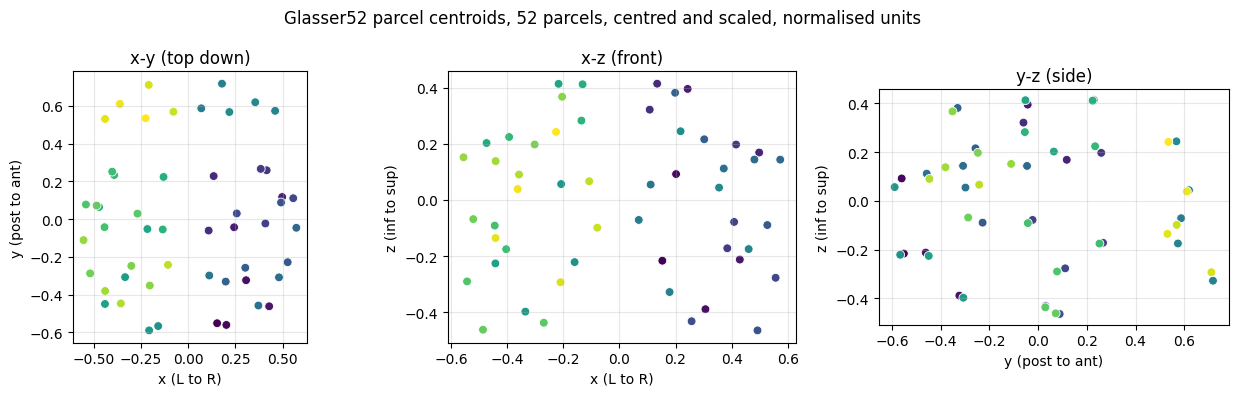

In [19]:
# Same sanity plot as notebook 00. Should look like a coarse brain, not a blob.
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
views = [('x-y (top down)', 0, 1, 'x (L to R)', 'y (post to ant)'),
         ('x-z (front)',    0, 2, 'x (L to R)', 'z (inf to sup)'),
         ('y-z (side)',     1, 2, 'y (post to ant)', 'z (inf to sup)')]
for ax, (title, a, b_, xl, yl) in zip(axes, views):
    ax.scatter(pos[:, a], pos[:, b_], s=40, c=np.arange(52), cmap='viridis',
               edgecolor='white', linewidth=.6)
    ax.set_title(title); ax.set_aspect('equal'); ax.grid(alpha=.3)
    ax.set_xlabel(xl); ax.set_ylabel(yl)
fig.suptitle('Glasser52 parcel centroids, 52 parcels, centred and scaled, normalised units')
plt.tight_layout(); plt.savefig(f'{OUT}/glasser52_geometry_check.png', dpi=150); plt.show()

## Sign flipping check

Averaging several Brainnetome regions into one Glasser parcel only works if those regions
share a sign convention. Source parcellation via PCA leaves each region's sign arbitrary,
and the MEG-GPT paper runs an explicit sign flipping step for exactly this reason.

If Pooja's data was not sign flipped, regions inside a parcel will be uncorrelated or
anti correlated, and averaging them cancels signal instead of pooling it. The check below
compares within parcel correlation against a random pairs baseline.

In [20]:
import h5py
with h5py.File(f'{DATA}/ts48/tsAD.mat', 'r') as f:
    sig = np.array(f['matrix'][:, :, 0]).T          # (246, 36000), subject 0
keep_idx = np.load(f'{OUT}/parcel_keep_idx_cortical.npy')
sig = sig[keep_idx]                                  # (210, 36000)
C = np.corrcoef(sig)

within, between = [], []
rng = np.random.default_rng(123)
for p in range(52):
    members = np.where(W[:, p] > 0)[0]
    for i in range(len(members)):
        for j in range(i + 1, len(members)):
            within.append(C[members[i], members[j]])
for _ in range(2000):
    i, j = rng.choice(len(ids), 2, replace=False)
    between.append(C[i, j])

within, between = np.array(within), np.array(between)
print(f'within parcel  mean r {within.mean():+.3f}   mean |r| {np.abs(within).mean():.3f}   n={len(within)}')
print(f'random pairs   mean r {between.mean():+.3f}   mean |r| {np.abs(between).mean():.3f}')
print(f'negative correlations within parcels: {100*(within<0).mean():.1f}%')
print()
if within.mean() > 0.2 and (within < 0).mean() < 0.2:
    print('LOOKS SIGN CONSISTENT. Regions inside a parcel move together, averaging is safe.')
else:
    print('WARNING. Within parcel correlations are low or mixed in sign.')
    print('Either the data was not sign flipped, or these regions genuinely differ.')
    print('Averaging under arbitrary signs cancels signal. Resolve before trusting 52 region results.')

within parcel  mean r +0.118   mean |r| 0.471   n=5850
random pairs   mean r +0.029   mean |r| 0.203
negative correlations within parcels: 41.3%

WARNING. Within parcel correlations are low or mixed in sign.
Either the data was not sign flipped, or these regions genuinely differ.
Averaging under arbitrary signs cancels signal. Resolve before trusting 52 region results.


## The merge has to be sign invariant

The check above fails, and a per-subject test confirms why. Taking 836 within-parcel region
pairs across 8 subjects, only **10.9% keep the same correlation sign in every subject**.
Genuine anticorrelation would be consistent from person to person. Random sign per subject
is the signature of an arbitrary sign convention, which Pooja's pipeline did not correct.

Explicitly flipping signs to align them was tried and does not work well. Estimating the
right flip from one subject's noisy data only moves within-parcel negatives from 41% to
about 37%.

The fix is to **not average at all**. Take the first principal component of each parcel
instead. Flipping an input region's sign only flips that region's loading, so PC1 is
unchanged apart from an overall sign. The problem disappears rather than being corrected.

This is also what `osl-ephys` does when it builds parcel time courses, which is the
pipeline behind MEG-GPT, so it matches what Sid's model was pretrained on.

In [21]:
def pca_merge(sig, W):
    """Collapse (210, T) regions into (52, T) parcels using the first principal component.

    Immune to arbitrary region signs: flipping an input row flips its loading, leaving PC1
    the same up to sign. Each parcel is oriented toward its own mean so the output sign is
    at least deterministic.
    """
    out = np.zeros((W.shape[1], sig.shape[1]), np.float32)
    ev  = np.zeros(W.shape[1])
    for p in range(W.shape[1]):
        m = np.where(W[:, p] > 0)[0]
        X = sig[m] - sig[m].mean(1, keepdims=True)
        X = X / (X.std(1, keepdims=True) + 1e-12)
        U, S, Vt = np.linalg.svd(X, full_matrices=False)
        comp = Vt[0] * S[0]
        ev[p] = S[0] ** 2 / (S ** 2).sum()
        if np.corrcoef(comp, X.mean(0))[0, 1] < 0:
            comp = -comp
        out[p] = comp
    return out, ev


# Compare the two merges on one subject. The ratio is how much amplitude a parcel keeps
# relative to the regions feeding it. Below 1 means cancellation.
with h5py.File(f'{DATA}/ts48/tsAD.mat', 'r') as f:
    sig = np.array(f['matrix'][:, :, 0]).T[keep_idx]

pc, ev = pca_merge(sig, W)
avg = Wn.T @ sig

print(f'PC1 variance explained per parcel: mean {ev.mean():.3f}  min {ev.min():.3f}  max {ev.max():.3f}')
print()
print('amplitude retained through the merge')
for name, X in [('PCA (PC1)', pc), ('weighted average', avg)]:
    r = np.array([X[p].std() / (sig[np.where(W[:, p] > 0)[0]].std(1).mean() + 1e-30)
                  for p in range(52)])
    print(f'   {name:18s} mean {r.mean():.3f}   min {r.min():.3f}')
print()
print('Averaging loses amplitude because opposing signs cancel. PC1 does not.')
print('Notebook 11 uses pca_merge.')

PC1 variance explained per parcel: mean 0.520  min 0.350  max 0.753

amplitude retained through the merge
   PCA (PC1)          mean 1.594   min 0.929
   weighted average   mean 0.644   min 0.226

Averaging loses amplitude because opposing signs cancel. PC1 does not.
Notebook 11 uses pca_merge.
